In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from imblearn.over_sampling import SMOTE
from catboost import CatBoostClassifier
import warnings
warnings.filterwarnings("ignore")


In [8]:
df = pd.read_csv("E:\\High_Volatility_Project\\dataset.txt")  
df.dropna(inplace=True)
df = df.rename(columns=lambda x: x.strip())


In [9]:
df['volatility'] = (df['High'] - df['Low']) / df['Open']
df['target'] = (df['volatility'].shift(-1) > 0.03).astype(int)
df.dropna(inplace=True)  # Remove last row with NaN label


In [10]:
df['return'] = df['Close'].pct_change()
df['sma_5'] = df['Close'].rolling(5).mean()
df['sma_10'] = df['Close'].rolling(10).mean()
df['ema_5'] = df['Close'].ewm(span=5).mean()
df['rsi'] = 100 - (100 / (1 + df['return'].rolling(14).mean() / df['return'].rolling(14).std()))
df['price_change'] = df['Close'] - df['Open']
df = df.dropna()


In [11]:
X = df[['Open', 'High', 'Low', 'Close', 'Volume', 'sma_5', 'sma_10', 'ema_5', 'rsi', 'price_change']]
y = df['target']


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train_scaled, y_train)


In [14]:
model = CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6, verbose=100)
model.fit(X_train_res, y_train_res)


0:	learn: 0.6748435	total: 154ms	remaining: 1m 16s
100:	learn: 0.4522918	total: 488ms	remaining: 1.93s
200:	learn: 0.4033231	total: 768ms	remaining: 1.14s
300:	learn: 0.3514135	total: 1.05s	remaining: 692ms
400:	learn: 0.3095636	total: 1.33s	remaining: 328ms
499:	learn: 0.2757457	total: 1.61s	remaining: 0us


In [15]:
y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.7693726937269373
              precision    recall  f1-score   support

           0       0.75      0.85      0.80       290
           1       0.80      0.68      0.73       252

    accuracy                           0.77       542
   macro avg       0.77      0.76      0.76       542
weighted avg       0.77      0.77      0.77       542



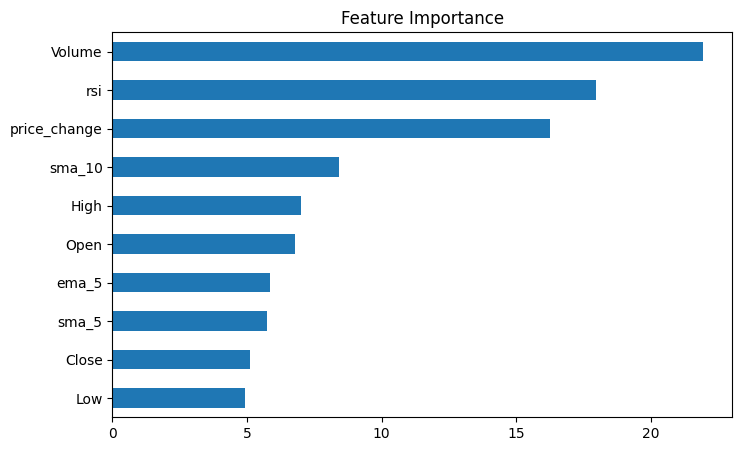

In [16]:
feat_imp = pd.Series(model.feature_importances_, index=X.columns)
feat_imp.sort_values().plot(kind='barh', figsize=(8,5), title='Feature Importance')
plt.show()


In [17]:
import joblib
joblib.dump(model, 'volatility_predictor_catboost.pkl')


['volatility_predictor_catboost.pkl']